<a href="https://colab.research.google.com/github/fathiobiedmohammedalamin-byte/VISIONAI/blob/main/Bankak_Reviews_maram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries loaded successfully.
Project: Bankak NLP Analytics
Device: GPU
Output directory: /content/Bankak_Research_Results

BANKAK GOOGLE PLAY REVIEW COLLECTION

How many reviews do you want to collect? 1000

Collection settings:
Application ID: com.mode.bok.ui
Language: ar
Country: sd
Requested reviews: 1000
Sorting: Newest first

Starting Google Play collection...

Page 1 | Collected: 0 / 1000
New reviews: 200
Total collected: 200

Page 2 | Collected: 200 / 1000
New reviews: 200
Total collected: 400

Page 3 | Collected: 400 / 1000
New reviews: 200
Total collected: 600

Page 4 | Collected: 600 / 1000
New reviews: 200
Total collected: 800

Page 5 | Collected: 800 / 1000
New reviews: 200
Total collected: 1000

Collection completed.
Requested: 1000
Actually collected: 1000

Data cleaning completed.
Valid reviews: 405

Loading CAMeLBERT sentiment model...


config.json:   0%|          | 0.00/468 [00:00<?, ?B/s]

Model label mapping:
{0: 'LABEL_0', 1: 'LABEL_1'}


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (38 outputs left out)

  0%|          | 0/3 [00:00<?, ?it/s]


Starting emotion detection...


  0%|          | 0/51 [00:00<?, ?it/s]


Emotion distribution:
Emotion
confusion and uncertainty     276
happiness and satisfaction     74
trust and confidence           36
neutral emotion                14
fear and security concerns      3
sadness and disappointment      2
Name: count, dtype: int64


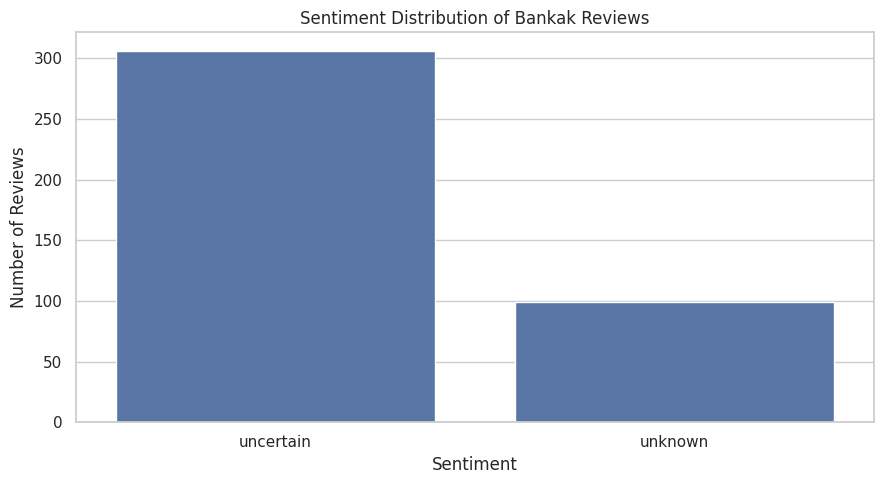

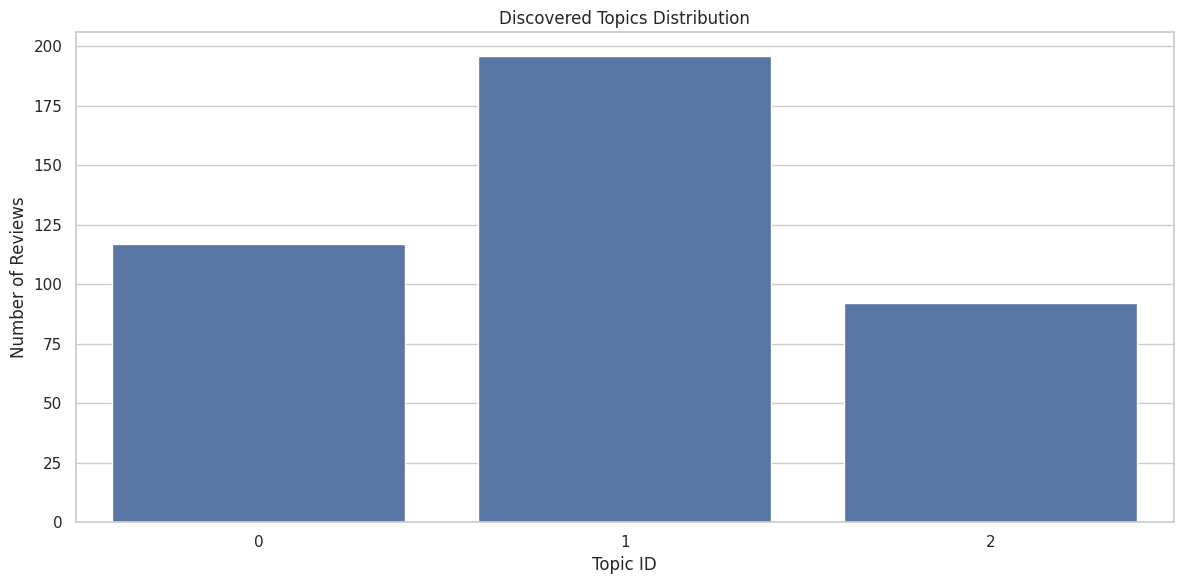

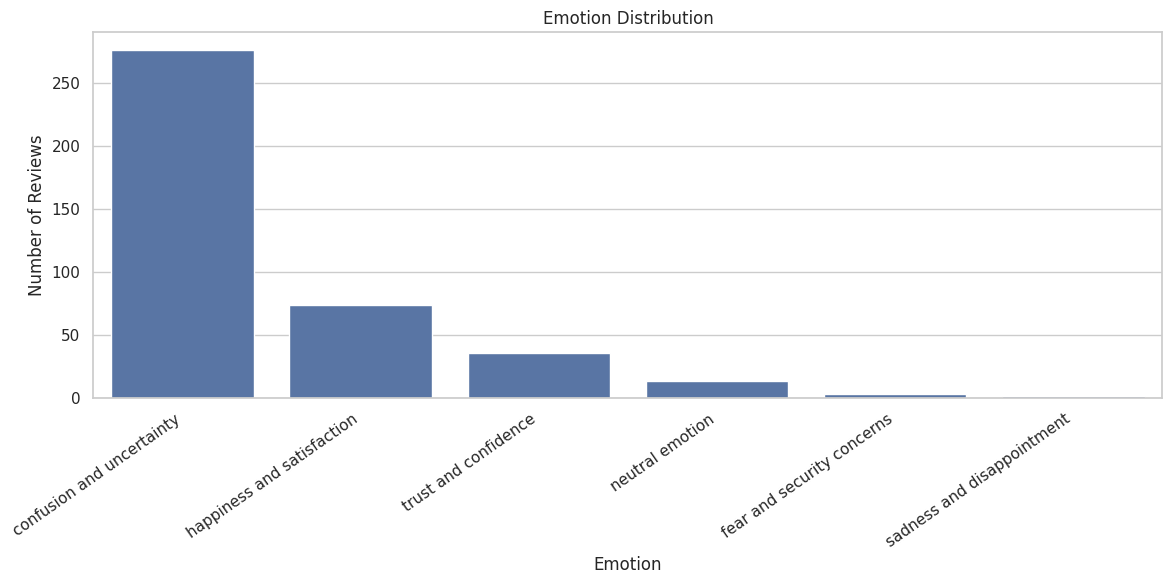

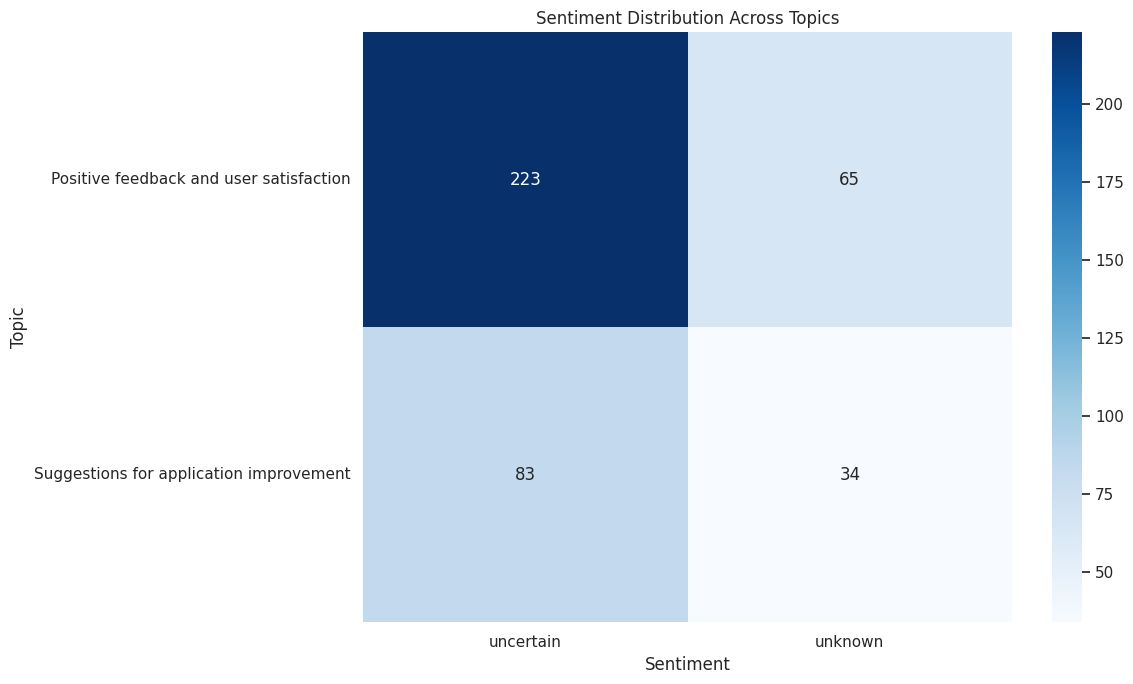

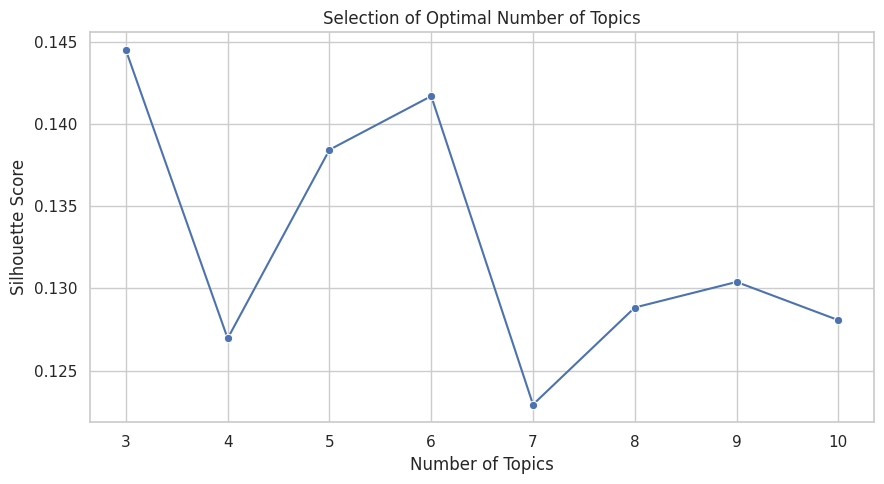


BANKAK NLP ANALYSIS COMPLETED SUCCESSFULLY

Requested reviews: 1000
Collected reviews: 1000
Cleaned reviews: 405
Discovered topics: 3

Sentiment distribution:
Sentiment
uncertain    306
unknown       99
Name: count, dtype: int64

Emotion distribution:
Emotion
confusion and uncertainty     276
happiness and satisfaction     74
trust and confidence           36
neutral emotion                14
fear and security concerns      3
sadness and disappointment      2
Name: count, dtype: int64

Topic results:
 Topic_ID  Review_Count                     Topic_Label_English                                                               Topic_Keywords_Arabic
        0           117 Suggestions for application improvement               بنكك, تطبيق, جدا, التطبيق, يفتح, فتح, حساب, يعمل, لماذا, بنك, سي, سيء
        1           196 Positive feedback and user satisfaction      جدا, ممتاز, تطبيق, جميل, جيد, جدا جدا, رايع, جيده, ممتاز جدا, الله, شكرا, تمام
        2            92 Positive feedback and use

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download request sent.


In [1]:


# ================================================================
# BANKAK NLP ANALYTICS PLATFORM
# Master's Research Project
#
# Google Play Data Collection
# Arabic Text Preprocessing
# Sentiment Analysis
# Topic Discovery
# Emotion Detection
# Statistical Analysis
# Charts and CSV Reports
# Automatic ZIP Download
# ================================================================


# 1. INSTALL LIBRARIES
# ================================================================

!pip -q install google-play-scraper transformers sentence-transformers scikit-learn pandas numpy matplotlib seaborn torch tqdm


# 2. IMPORT LIBRARIES
# ================================================================

import os
import re
import gc
import json
import time
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from tqdm.auto import tqdm
from datetime import datetime
from IPython.display import display

warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")


# 3. PROJECT CONFIGURATION
# ================================================================

APP_ID = "com.mode.bok.ui"

LANGUAGE = "ar"
COUNTRY = "sd"

SENTIMENT_MODEL = (
    "CAMeL-Lab/bert-base-arabic-camelbert-da"
)

EMBEDDING_MODEL = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

ZERO_SHOT_MODEL = (
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

CONFIDENCE_THRESHOLD = 0.60

MIN_TOPICS = 3
MAX_TOPICS = 10

OUTPUT_DIR = "/content/Bankak_Research_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else -1

print("Project:", "Bankak NLP Analytics")
print("Device:", "GPU" if DEVICE == 0 else "CPU")
print("Output directory:", OUTPUT_DIR)


# 4. USER INPUT - REVIEW COLLECTION SETTINGS
# ================================================================

print("\n" + "=" * 60)
print("BANKAK GOOGLE PLAY REVIEW COLLECTION")
print("=" * 60)

while True:
    try:
        REQUESTED_COUNT = int(
            input(
                "\nHow many reviews do you want to collect? "
            )
        )

        if REQUESTED_COUNT < 1:
            print("Please enter a number greater than zero.")
            continue

        break

    except ValueError:
        print("Please enter a valid whole number.")

print("\nCollection settings:")
print("Application ID:", APP_ID)
print("Language:", LANGUAGE)
print("Country:", COUNTRY)
print("Requested reviews:", REQUESTED_COUNT)
print("Sorting: Newest first")

if REQUESTED_COUNT > 20000:
    print(
        "\nWarning: Large collection requests may take longer "
        "or be limited by Google Play."
    )


# 5. COLLECT REVIEWS FROM GOOGLE PLAY
# ================================================================

from google_play_scraper import reviews, Sort

print("\nStarting Google Play collection...")

all_reviews = []
seen_ids = set()

continuation_token = None
page_number = 0

BATCH_SIZE = 200

while len(all_reviews) < REQUESTED_COUNT:

    remaining = REQUESTED_COUNT - len(all_reviews)

    current_batch_size = min(
        BATCH_SIZE,
        remaining
    )

    page_number += 1

    print(
        f"\nPage {page_number} | "
        f"Collected: {len(all_reviews)} / {REQUESTED_COUNT}"
    )

    try

        batch, next_token = reviews(
            APP_ID,
            lang=LANGUAGE,
            country=COUNTRY,
            sort=Sort.NEWEST,
            count=current_batch_size,
            continuation_token=continuation_token
        )

    except Exception as error:

        print("\nGoogle Play collection error:")
        print(str(error))
        break

    if not batch:
        print("No more reviews available.")
        break

    new_reviews = []

    for review in batch:

        review_id = review.get("reviewId")

        if not review_id:

            review_id = (
                str(review.get("userName", ""))
                + str(review.get("at", ""))
                + str(review.get("content", ""))
            )

        if review_id not in seen_ids:

            seen_ids.add(review_id)
            new_reviews.append(review)

    all_reviews.extend(new_reviews)

    print("New reviews:", len(new_reviews))
    print("Total collected:", len(all_reviews))

    if len(new_reviews) == 0:
        print("No new unique reviews. Stopping collection.")
        break

    continuation_token = next_token

    if continuation_token is None:
        print("No further page token was returned.")
        break

    time.sleep(0.7)


# 6. CREATE RAW DATASET
# ================================================================

df = pd.DataFrame(all_reviews)

if df.empty:
    raise ValueError(
        "No reviews were collected. "
        "Check the connection or try again later."
    )

df["Original_Review"] = (
    df["content"]
    .fillna("")
    .astype(str)
)

RAW_FILE = os.path.join(
    OUTPUT_DIR,
    "01_Raw_Google_Play_Reviews.csv"
)

df.to_csv(
    RAW_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("\nCollection completed.")
print("Requested:", REQUESTED_COUNT)
print("Actually collected:", len(df))


# 7. ARABIC TEXT CLEANING
# ================================================================

arabic_diacritics = re.compile(
    r"[\u0617-\u061A\u064B-\u0652\u0670\u06D6-\u06ED]"
)

def clean_arabic_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Remove email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    # Remove diacritics and Tatweel
    text = re.sub(
        arabic_diacritics,
        "",
        text
    )

    text = text.replace("ـ", "")

    # Normalize Arabic letters
    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "و", text)
    text = re.sub("ئ", "ي", text)

    # Remove mentions and hashtags
    text = re.sub(
        r"[@#]\S+",
        " ",
        text
    )

    # Keep Arabic, English and numbers
    text = re.sub(
        r"[^\u0600-\u06FFa-zA-Z0-9\s]",
        " ",
        text
    )

    # Normalize spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


df["Cleaned_Review"] = (
    df["Original_Review"]
    .apply(clean_arabic_text)
)

# Remove empty reviews
df = df[
    df["Cleaned_Review"].str.len() > 0
].copy()

# Remove duplicate text
df = df.drop_duplicates(
    subset=["Cleaned_Review"]
).reset_index(drop=True)

# Remove very short reviews
df = df[
    df["Cleaned_Review"].str.split().str.len() >= 2
].reset_index(drop=True)

if len(df) < 10:
    raise ValueError(
        "Fewer than 10 valid reviews remain after cleaning."
    )

documents = df["Cleaned_Review"].tolist()

print("\nData cleaning completed.")
print("Valid reviews:", len(df))


# 8. SENTIMENT ANALYSIS - CAMELBERT
# ================================================================

from transformers import pipeline, AutoConfig

print("\nLoading CAMeLBERT sentiment model...")

sentiment_config = AutoConfig.from_pretrained(
    SENTIMENT_MODEL
)

print("Model label mapping:")
print(sentiment_config.id2label)

sentiment_pipeline = pipeline(
    "text-classification",
    model=SENTIMENT_MODEL,
    tokenizer=SENTIMENT_MODEL,
    device=DEVICE
)

sentiment_results = []

SENTIMENT_BATCH_SIZE = 16 if DEVICE == 0 else 8

print("\nRunning sentiment analysis...")

for start in tqdm(
    range(0, len(documents), SENTIMENT_BATCH_SIZE)
):

    batch = documents[
        start:start + SENTIMENT_BATCH_SIZE
    ]

    predictions = sentiment_pipeline(
        batch,
        truncation=True,
        max_length=256,
        batch_size=SENTIMENT_BATCH_SIZE
    )

    sentiment_results.extend(predictions)


def normalize_sentiment(label):

    label = str(label).lower()

    if "positive" in label:
        return "positive"

    if "negative" in label:
        return "negative"

    if "neutral" in label:
        return "neutral"

    match = re.search(
        r"(\d+)",
        label
    )

    if match:

        label_id = int(match.group(1))

        actual_label = str(
            sentiment_config.id2label.get(
                label_id,
                ""
            )
        ).lower()

        if "positive" in actual_label:
            return "positive"

        if "negative" in actual_label:
            return "negative"

        if "neutral" in actual_label:
            return "neutral"

    return "unknown"


df["Sentiment_Raw"] = [
    normalize_sentiment(result["label"])
    for result in sentiment_results
]

df["Sentiment_Confidence"] = [
    float(result["score"])
    for result in sentiment_results
]

df["Sentiment"] = np.where(
    df["Sentiment_Confidence"] < CONFIDENCE_THRESHOLD,
    "uncertain",
    df["Sentiment_Raw"]
)

print("\nSentiment results:")
print(df["Sentiment"].value_counts())

# Release sentiment model memory
del sentiment_pipeline
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# 9. TEXT EMBEDDINGS
# ================================================================

from sentence_transformers import SentenceTransformer

print("\nLoading embedding model...")

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

print("Generating embeddings...")

embeddings = embedding_model.encode(
    documents,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding shape:", embeddings.shape)

del embedding_model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# 10. AUTOMATIC TOPIC DISCOVERY - KMEANS
# ================================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

number_of_reviews = len(documents)

possible_k = list(
    range(
        MIN_TOPICS,
        min(MAX_TOPICS, number_of_reviews - 1) + 1
    )
)

if not possible_k:
    raise ValueError(
        "Not enough reviews for topic discovery."
    )

print("\nTesting different topic numbers...")

silhouette_results = []

sample_size = min(
    500,
    number_of_reviews
)

for k in possible_k:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(
        embeddings
    )

    try:

        score = silhouette_score(
            embeddings,
            cluster_labels,
            sample_size=sample_size,
            random_state=42
        )

        silhouette_results.append({
            "Number_of_Topics": k,
            "Silhouette_Score": score
        })

        print(
            f"K={k} | Silhouette Score={score:.4f}"
        )

    except Exception as error:

        print(
            f"K={k} | Silhouette calculation skipped: {error}"
        )

if not silhouette_results:

    best_k = min(
        5,
        number_of_reviews - 1
    )

    silhouette_df = pd.DataFrame(
        columns=[
            "Number_of_Topics",
            "Silhouette_Score"
        ]
    )

    print(
        "Could not calculate silhouette scores. "
        "Using a fallback topic count:",
        best_k
    )

else:

    silhouette_df = pd.DataFrame(
        silhouette_results
    )

    best_k = int(
        silhouette_df.loc[
            silhouette_df["Silhouette_Score"].idxmax(),
            "Number_of_Topics"
        ]
    )

print("\nSelected number of topics:", best_k)

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

topic_ids = kmeans_model.fit_predict(
    embeddings
)

df["Topic_ID"] = topic_ids

print("\nTopic distribution:")
print(
    df["Topic_ID"].value_counts().sort_index()
)


# 11. TOPIC KEYWORD EXTRACTION - TF-IDF
# ================================================================

from sklearn.feature_extraction.text import TfidfVectorizer

arabic_stopwords = [
    "في", "من", "على", "الى", "إلى", "عن",
    "هذا", "هذه", "ذلك", "تلك", "هو", "هي",
    "انا", "أنا", "نحن", "انت", "أنت",
    "كان", "كانت", "يكون", "مع", "ما", "لا",
    "لم", "لن", "قد", "كل", "بعد", "قبل",
    "او", "أو", "ثم", "كما", "بين", "عند",
    "عليه", "عليها", "لها", "له", "به", "بها",
    "يا", "والله", "لكن", "حتى", "اذا", "إذا",
    "الذي", "التي", "الذين", "ان", "أن",
    "انه", "إنه", "انها", "إنها"
]

vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w\w+\b",
    stop_words=arabic_stopwords,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    max_features=15000,
    sublinear_tf=True
)

try:

    tfidf_matrix = vectorizer.fit_transform(
        documents
    )

except ValueError:

    print(
        "Using fallback TF-IDF configuration..."
    )

    vectorizer = TfidfVectorizer(
        token_pattern=r"(?u)\b\w+\b",
        min_df=1,
        max_df=1.0,
        ngram_range=(1, 2),
        max_features=15000
    )

    tfidf_matrix = vectorizer.fit_transform(
        documents
    )


feature_names = np.array(
    vectorizer.get_feature_names_out()
)

topic_records = []

for topic_id in sorted(
    df["Topic_ID"].unique()
):

    topic_indices = np.where(
        df["Topic_ID"].values == topic_id
    )[0]

    topic_matrix = tfidf_matrix[
        topic_indices
    ]

    mean_scores = np.asarray(
        topic_matrix.mean(axis=0)
    ).ravel()

    top_indices = mean_scores.argsort()[::-1][:12]

    keywords = [
        feature_names[i]
        for i in top_indices
        if mean_scores[i] > 0
    ]

    topic_records.append({

        "Topic_ID": int(topic_id),

        "Review_Count": int(
            len(topic_indices)
        ),

        "Topic_Keywords_Arabic": ", ".join(
            keywords
        ),

        "Topic_Name": (
            "Topic "
            + str(topic_id)
            + " - "
            + ", ".join(keywords[:3])
        )
    })


topics_df = pd.DataFrame(
    topic_records
)

topic_name_map = dict(
    zip(
        topics_df["Topic_ID"],
        topics_df["Topic_Name"]
    )
)

df["Topic_Name"] = df["Topic_ID"].map(
    topic_name_map
)

print("\nDiscovered topics:")

print(
    topics_df[
        [
            "Topic_ID",
            "Review_Count",
            "Topic_Keywords_Arabic"
        ]
    ].to_string(index=False)
)


# 12. ZERO-SHOT TOPIC LABELING
# ================================================================

print("\nLoading zero-shot classification model...")

zero_shot_pipeline = pipeline(
    "zero-shot-classification",
    model=ZERO_SHOT_MODEL,
    device=DEVICE
)

topic_candidates = [
    "Application performance and speed",
    "Login and account access problems",
    "Money transfers and financial transactions",
    "Payment and bill payment services",
    "User interface and application design",
    "Technical errors and application crashes",
    "Customer service and support",
    "Security and account protection",
    "Positive feedback and user satisfaction",
    "Suggestions for application improvement"
]

topic_labels = []

print("\nClassifying topics...")

for _, row in tqdm(
    topics_df.iterrows(),
    total=len(topics_df)
):

    topic_text = (
        "Customer reviews discussing: "
        + str(row["Topic_Keywords_Arabic"])
    )

    if len(topic_text.strip()) < 10:

        topic_labels.append("Unclassified")
        continue

    try:

        result = zero_shot_pipeline(
            topic_text,
            candidate_labels=topic_candidates,
            multi_label=False,
            truncation=True
        )

        topic_labels.append(
            result["labels"][0]
        )

    except Exception as error:

        print(
            "Topic classification warning:",
            error
        )

        topic_labels.append("Unclassified")


topics_df["Topic_Label_English"] = topic_labels

topic_label_map = dict(
    zip(
        topics_df["Topic_ID"],
        topics_df["Topic_Label_English"]
    )
)

df["Topic_Label_English"] = df["Topic_ID"].map(
    topic_label_map
)


# 13. EMOTION DETECTION
# ================================================================

emotion_candidates = [
    "happiness and satisfaction",
    "anger and frustration",
    "sadness and disappointment",
    "fear and security concerns",
    "trust and confidence",
    "confusion and uncertainty",
    "neutral emotion"
]

print("\nStarting emotion detection...")

emotion_results = []

EMOTION_BATCH_SIZE = 8 if DEVICE == 0 else 4

for start in tqdm(
    range(0, len(documents), EMOTION_BATCH_SIZE)
):

    batch = documents[
        start:start + EMOTION_BATCH_SIZE
    ]

    try:

        predictions = zero_shot_pipeline(
            batch,
            candidate_labels=emotion_candidates,
            multi_label=False,
            batch_size=EMOTION_BATCH_SIZE,
            truncation=True
        )

        if isinstance(predictions, dict):
            predictions = [predictions]

        emotion_results.extend(predictions)

    except Exception as error:

        print(
            "Emotion analysis error:",
            error
        )

        for text in batch:

            emotion_results.append({
                "labels": ["unclassified"],
                "scores": [0.0]
            })


df["Emotion"] = [
    result["labels"][0]
    for result in emotion_results
]

df["Emotion_Confidence"] = [
    float(result["scores"][0])
    for result in emotion_results
]

print("\nEmotion distribution:")
print(df["Emotion"].value_counts())


# 14. STATISTICAL ANALYSIS
# ================================================================

sentiment_summary = (
    df["Sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Review_Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Review_Count"]
    / len(df) * 100
).round(2)


topic_summary = (
    df.groupby(
        [
            "Topic_ID",
            "Topic_Name",
            "Topic_Label_English"
        ]
    )
    .size()
    .reset_index(name="Review_Count")
)

topic_summary["Percentage"] = (
    topic_summary["Review_Count"]
    / len(df) * 100
).round(2)


emotion_summary = (
    df["Emotion"]
    .value_counts()
    .rename_axis("Emotion")
    .reset_index(name="Review_Count")
)

emotion_summary["Percentage"] = (
    emotion_summary["Review_Count"]
    / len(df) * 100
).round(2)


sentiment_by_topic = pd.crosstab(
    df["Topic_Label_English"],
    df["Sentiment"]
)

emotion_by_topic = pd.crosstab(
    df["Topic_Label_English"],
    df["Emotion"]
)


# 15. VISUALIZATIONS
# ================================================================

sns.set_theme(
    style="whitegrid"
)

# Sentiment distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    data=sentiment_summary,
    x="Sentiment",
    y="Review_Count"
)

plt.title(
    "Sentiment Distribution of Bankak Reviews"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "01_Sentiment_Distribution.png"
    ),
    dpi=300
)

plt.show()


# Topic distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    data=topic_summary,
    x="Topic_ID",
    y="Review_Count"
)

plt.title(
    "Discovered Topics Distribution"
)

plt.xlabel("Topic ID")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "02_Topic_Distribution.png"
    ),
    dpi=300
)

plt.show()


# Emotion distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    data=emotion_summary,
    x="Emotion",
    y="Review_Count"
)

plt.title(
    "Emotion Distribution"
)

plt.xlabel("Emotion")
plt.ylabel("Number of Reviews")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "03_Emotion_Distribution.png"
    ),
    dpi=300
)

plt.show()


# Sentiment by topic
plt.figure(figsize=(12, 7))

sns.heatmap(
    sentiment_by_topic,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Sentiment Distribution Across Topics"
)

plt.xlabel("Sentiment")
plt.ylabel("Topic")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "04_Sentiment_By_Topic.png"
    ),
    dpi=300
)

plt.show()


# Topic selection scores
if not silhouette_df.empty:

    plt.figure(figsize=(9, 5))

    sns.lineplot(
        data=silhouette_df,
        x="Number_of_Topics",
        y="Silhouette_Score",
        marker="o"
    )

    plt.title(
        "Selection of Optimal Number of Topics"
    )

    plt.xlabel("Number of Topics")
    plt.ylabel("Silhouette Score")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "05_Topic_Selection.png"
        ),
        dpi=300
    )

    plt.show()


# 16. SAVE CSV REPORTS
# ================================================================

reports = {

    "02_Complete_Reviews_Analysis.csv": df,

    "03_Discovered_Topics.csv": topics_df,

    "04_Sentiment_Summary.csv": sentiment_summary,

    "05_Topic_Summary.csv": topic_summary,

    "06_Emotion_Summary.csv": emotion_summary,

    "09_Topic_Selection_Scores.csv": silhouette_df
}

for filename, dataframe in reports.items():

    dataframe.to_csv(
        os.path.join(
            OUTPUT_DIR,
            filename
        ),
        index=False,
        encoding="utf-8-sig"
    )


sentiment_by_topic.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "07_Sentiment_By_Topic.csv"
    ),
    encoding="utf-8-sig"
)

emotion_by_topic.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "08_Emotion_By_Topic.csv"
    ),
    encoding="utf-8-sig"
)


# 17. RESEARCH SUMMARY
# ================================================================

research_summary = {

    "Project": (
        "Analysis of Bankak Application Users' Opinions "
        "and Impressions Using NLP and Sentiment Analysis"
    ),

    "Application_ID": APP_ID,

    "Data_Source": "Google Play",

    "Language": LANGUAGE,

    "Country": COUNTRY,

    "Requested_Reviews": int(REQUESTED_COUNT),

    "Downloaded_Reviews": int(len(all_reviews)),

    "Cleaned_Reviews": int(len(df)),

    "Embedding_Model": EMBEDDING_MODEL,

    "Sentiment_Model": SENTIMENT_MODEL,

    "Topic_Method": "K-Means Clustering",

    "Topic_Keyword_Method": "TF-IDF",

    "Zero_Shot_Model": ZERO_SHOT_MODEL,

    "Number_of_Discovered_Topics": int(best_k),

    "Sentiment_Confidence_Threshold": (
        CONFIDENCE_THRESHOLD
    ),

    "Collection_Sort": "Newest first",

    "Analysis_Date": datetime.now().isoformat()
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "10_Research_Summary.json"
    ),
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        research_summary,
        file,
        ensure_ascii=False,
        indent=4
    )


# 18. CREATE ZIP FILE
# ================================================================

ZIP_PATH = (
    "/content/Bankak_Research_Results.zip"
)

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files_list in os.walk(
        OUTPUT_DIR
    ):

        for file in files_list:

            full_path = os.path.join(
                root,
                file
            )

            relative_path = os.path.relpath(
                full_path,
                OUTPUT_DIR
            )

            zipf.write(
                full_path,
                arcname=relative_path
            )


# 19. VERIFY ZIP FILE
# ================================================================

if not os.path.exists(ZIP_PATH):

    raise FileNotFoundError(
        "ZIP file was not created."
    )

zip_size_mb = (
    os.path.getsize(ZIP_PATH)
    / (1024 * 1024)
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zipf:

    bad_file = zipf.testzip()

    if bad_file is not None:

        raise ValueError(
            f"ZIP verification failed: {bad_file}"
        )

    zip_contents = zipf.namelist()


# 20. FINAL RESEARCH RESULTS
# ================================================================

print("\n" + "=" * 60)

print(
    "BANKAK NLP ANALYSIS COMPLETED SUCCESSFULLY"
)

print("=" * 60)

print(
    "\nRequested reviews:",
    REQUESTED_COUNT
)

print(
    "Collected reviews:",
    len(all_reviews)
)

print(
    "Cleaned reviews:",
    len(df)
)

print(
    "Discovered topics:",
    best_k
)

print("\nSentiment distribution:")

print(
    df["Sentiment"].value_counts()
)

print("\nEmotion distribution:")

print(
    df["Emotion"].value_counts()
)

print("\nTopic results:")

print(
    topics_df[
        [
            "Topic_ID",
            "Review_Count",
            "Topic_Label_English",
            "Topic_Keywords_Arabic"
        ]
    ].to_string(index=False)
)

print("\nZIP size:", round(zip_size_mb, 2), "MB")

print(
    "Files inside ZIP:",
    len(zip_contents)
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nZIP file:")
print(ZIP_PATH)


# 21. AUTOMATIC DOWNLOAD
# ================================================================

from google.colab import files

print("\nPreparing your research files for download...")

files.download(ZIP_PATH)

print("\nDownload request sent.")